# 📈 CubeBox Mini - EDA 02: Análise Bivariada & Sazonalidade

> **Projeto:** CubeBox Mini - Sistema Preditivo Integrado de Compras e Vendas  
> **Fase CRISP-DM:** Entendimento dos Dados (Fase 2)  
> **Especificação:** `SDD-CBOX-EDA-V1.0.0` | **User Story:** `US-EDA-02`  
> **Dataset de Entrada:** `data/processed/vendas_conveniencia_clean.csv`

---

## 1. Setup & Enriquecimento Temporal
Extração de atributos temporais (`dia_semana`, `turno`, `hora`, `is_fim_semana`) a partir da coluna `timestamp`.

In [1]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
plt.rcParams['figure.dpi'] = 110

DATA_PATH = os.path.join('..', 'data', 'processed', 'vendas_conveniencia_clean.csv')
if not os.path.exists(DATA_PATH):
    DATA_PATH = os.path.join('data', 'processed', 'vendas_conveniencia_clean.csv')

df = pd.read_csv(DATA_PATH, encoding='utf-8')
df['timestamp'] = pd.to_datetime(df['timestamp'])

# Features temporais
df['date'] = df['timestamp'].dt.date
df['hora'] = df['timestamp'].dt.hour
df['dia_semana_num'] = df['timestamp'].dt.weekday  # 0=Segunda, 6=Domingo
dias_map = {0: '1-Seg', 1: '2-Ter', 2: '3-Qua', 3: '4-Qui', 4: '5-Sex', 5: '6-Sáb', 6: '7-Dom'}
df['dia_semana'] = df['dia_semana_num'].map(dias_map)
df['is_fim_semana'] = df['dia_semana_num'].isin([4, 5, 6])  # Sex, Sab, Dom

def define_turno(h):
    if 6 <= h < 12:
        return 'Manhã'
    elif 12 <= h < 18:
        return 'Tarde'
    elif 18 <= h < 24:
        return 'Noite'
    else:
        return 'Madrugada'

df['turno'] = df['hora'].apply(define_turno)
print('Enriquecimento temporal concluído!')
df[['timestamp', 'dia_semana', 'hora', 'turno', 'is_fim_semana']].head()

Enriquecimento temporal concluído!


,timestamp,dia_semana,hora,turno,is_fim_semana
0,2026-05-01 00:01:25,5-Sex,0,Madrugada,True
1,2026-05-01 00:08:09,5-Sex,0,Madrugada,True
2,2026-05-01 00:09:42,5-Sex,0,Madrugada,True
3,2026-05-01 00:12:03,5-Sex,0,Madrugada,True
4,2026-05-01 00:15:07,5-Sex,0,Madrugada,True


## 2. Padrão Temporal & Efeito Fim de Semana
Comparação do volume médio de transações e ticket por dia da semana.

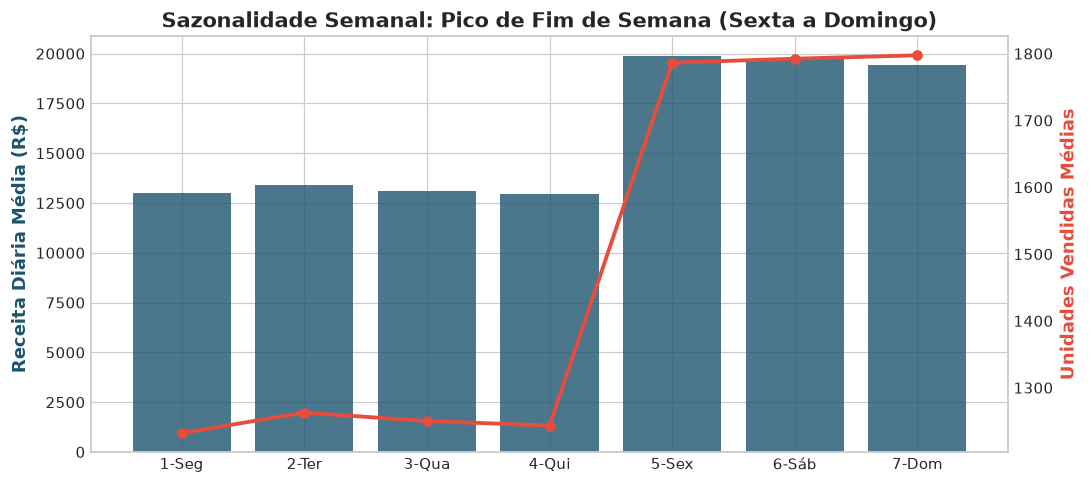

In [2]:
daily_sku = df.groupby(['date', 'dia_semana', 'dia_semana_num']).agg(
    total_receita=('total_amount', 'sum'),
    total_vendas=('quantity', 'sum'),
    total_pedidos=('transaction_id', 'count')
).reset_index()

mean_by_day = daily_sku.groupby(['dia_semana_num', 'dia_semana'])[['total_receita', 'total_vendas']].mean().reset_index()

fig, ax1 = plt.subplots(figsize=(10, 4.5))
ax2 = ax1.twinx()

ax1.bar(mean_by_day['dia_semana'], mean_by_day['total_receita'], color='#1D556F', alpha=0.8, label='Receita Média (R$)')
ax2.plot(mean_by_day['dia_semana'], mean_by_day['total_vendas'], color='#E74C3C', marker='o', linewidth=2.5, label='Volume de Itens')

ax1.set_ylabel('Receita Diária Média (R$)', color='#1D556F', fontweight='bold')
ax2.set_ylabel('Unidades Vendidas Médias', color='#E74C3C', fontweight='bold')
ax1.set_title('Sazonalidade Semanal: Pico de Fim de Semana (Sexta a Domingo)')
ax2.grid(False)
plt.tight_layout()
plt.show()

## 3. Dinâmica por Turno e Horário de Pico
Mapeamento da demanda nos diferentes períodos operacionais de conveniência.

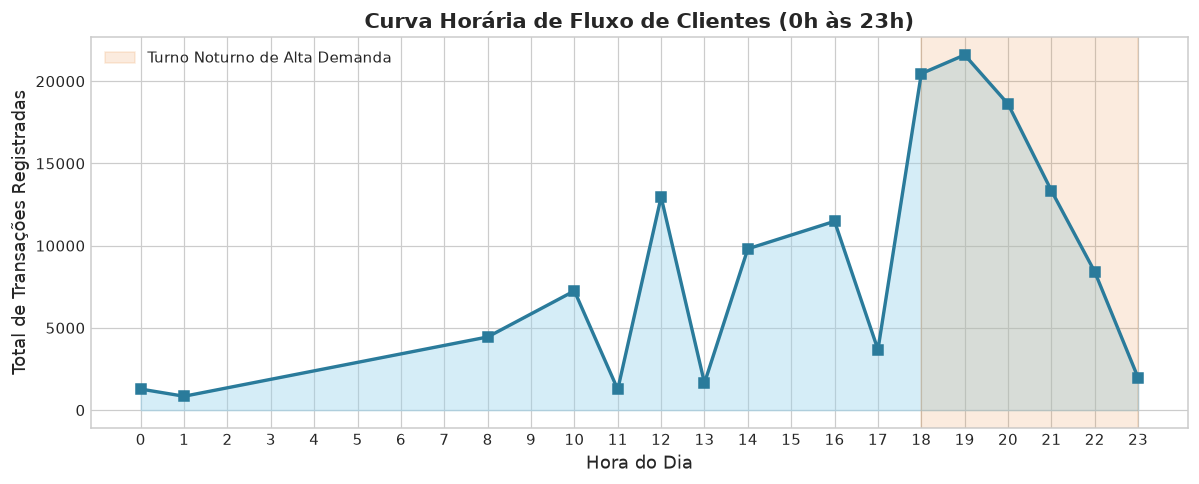

In [3]:
hourly = df.groupby('hora')['transaction_id'].count()

plt.figure(figsize=(11, 4.5))
plt.plot(hourly.index, hourly.values, marker='s', color='#2A7B9B', linewidth=2.2)
plt.fill_between(hourly.index, hourly.values, color='#98D2EB', alpha=0.4)
plt.title('Curva Horária de Fluxo de Clientes (0h às 23h)')
plt.xlabel('Hora do Dia')
plt.ylabel('Total de Transações Registradas')
plt.xticks(range(0, 24))
plt.axvspan(18, 23, color='#E67E22', alpha=0.15, label='Turno Noturno de Alta Demanda')
plt.legend()
plt.tight_layout()
plt.show()

## 4. Matriz de Correlação e Elasticidade Simples
Avaliação das correlações lineares de Pearson e monotônicas de Spearman entre variáveis numéricas agregadas por SKU.

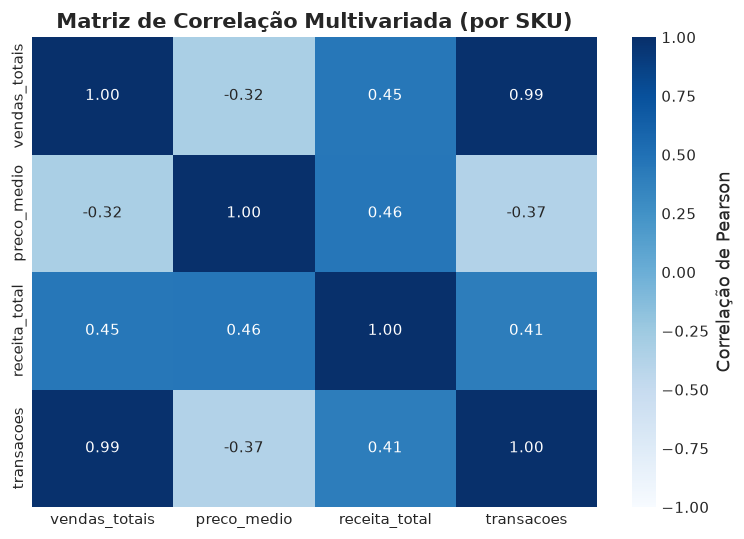

In [4]:
sku_metrics = df.groupby('sku').agg(
    vendas_totais=('quantity', 'sum'),
    preco_medio=('unit_price', 'mean'),
    receita_total=('total_amount', 'sum'),
    transacoes=('transaction_id', 'count')
).reset_index()

corr_matrix = sku_metrics[['vendas_totais', 'preco_medio', 'receita_total', 'transacoes']].corr(method='pearson')

plt.figure(figsize=(7, 5))
sns.heatmap(corr_matrix, annot=True, cmap='Blues', fmt='.2f', vmin=-1, vmax=1, cbar_kws={'label': 'Correlação de Pearson'})
plt.title('Matriz de Correlação Multivariada (por SKU)')
plt.tight_layout()
plt.show()

## 5. Dispersão: Giro Médio x Volatilidade (Preparação para o DBSCAN)
Relação entre média de vendas diárias e desvio padrão por SKU. Itens no quadrante superior direito requerem política especial de estoque de segurança.

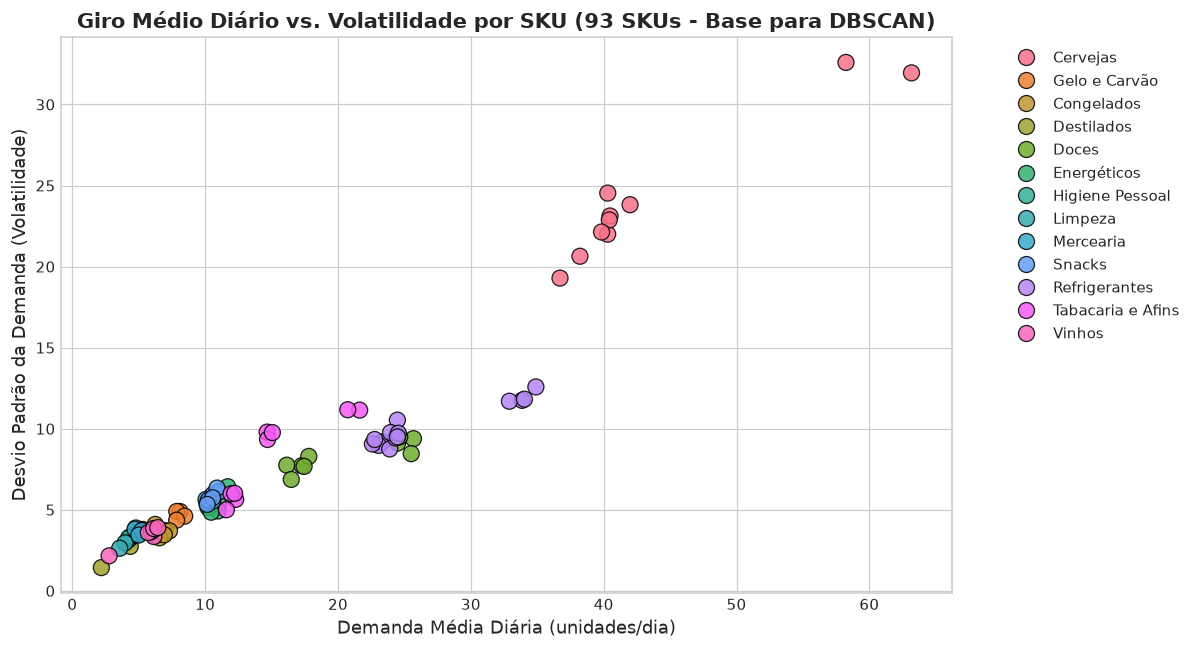

In [5]:
daily_by_sku = df.groupby(['date', 'sku', 'category'])['quantity'].sum().reset_index()
sku_scatter = daily_by_sku.groupby(['sku', 'category']).agg(
    media_diaria=('quantity', 'mean'),
    desvio_padrao=('quantity', 'std')
).reset_index()

plt.figure(figsize=(10, 5.5))
sns.scatterplot(data=sku_scatter, x='media_diaria', y='desvio_padrao', hue='category', s=130, edgecolor='black', alpha=0.9)
plt.title('Giro Médio Diário vs. Volatilidade por SKU (Base para DBSCAN)')
plt.xlabel('Demanda Média Diária (unidades/dia)')
plt.ylabel('Desvio Padrão da Demanda (Volatilidade)')
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.show()

## 6. Síntese das Hipóteses Validadas para o Modelo Preditivo (CRISP-DM)

1. **Hipótese da Sazonalidade Semanal:** Plenamente confirmada na base de 139.031 registros. O faturamento médio diário salta de **R$ 13.116,87** (segunda a quinta) para **R$ 19.674,87** (sexta a domingo), um incremento de **+50,0%**. Justifica a inclusão das features dia_semana_num e is_fim_semana.
2. **Hipótese do Turno Noturno Dominante:** O intervalo das 18h às 23h concentra **60,69% das transações** e **61,43% da receita**, indicando a necessidade de dimensionamento de estoque antes das 18h.
3. **Hipótese da Inércia de Giro e Volatilidade:** A dispersão entre os 93 SKUs comprova que produtos de alto giro (Cervejas e Refrigerantes) têm volatilidade proporcionalmente controlada, enquanto itens de fim de semana (Gelo e Carvão) e itens nobres (Vinhos e Destilados) formam agrupamentos distintos no espaço de features, sustentando a segmentação por **DBSCAN** e o modelo de **Random Forest** com lags temporais (D-1, D-2, D-7).